Python eda OF OLA 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# CSV ka actual path / filename yahan do
df = pd.read_csv("ola.csv")

# Dataset ke first 5 rows
df.head()

,Date,Time,Booking_ID,Booking_Status,Customer_ID,Vehicle_Type,Pickup_Location,Drop_Location,V_TAT,C_TAT,...,Canceled_Rides_by_Driver,Incomplete_Rides,Incomplete_Rides_Reason,Booking_Value,Payment_Method,Ride_Distance,Driver_Ratings,Customer_Rating,Vehicle Images,Unnamed: 20
0,26-07-2024,14:00:00,CNR7153255142,Canceled by Driver,CID713523,Prime Sedan,Tumkur Road,RT Nagar,NaN,NaN,...,Personal & Car related issue,NaN,NaN,444,NaN,0,NaN,NaN,#NAME?,NaN
1,25-07-2024,22:20:00,CNR2940424040,Success,CID225428,Bike,Magadi Road,Varthur,203.0,30.0,...,NaN,No,NaN,158,Cash,13,4.1,4.0,https://cdn-icons-png.flaticon.com/128/9983/99...,NaN
2,30-07-2024,19:59:00,CNR2982357879,Success,CID270156,Prime SUV,Sahakar Nagar,Varthur,238.0,130.0,...,NaN,No,NaN,386,UPI,40,4.2,4.8,"=XLOOKUP(F4,Sheet2!A:A,Sheet2!B:B)",NaN
3,22-07-2024,03:15:00,CNR2395710036,Canceled by Customer,CID581320,eBike,HSR Layout,Vijayanagar,NaN,NaN,...,NaN,NaN,NaN,384,NaN,0,NaN,NaN,#NAME?,NaN
4,02-07-2024,09:02:00,CNR1797421769,Success,CID939555,Mini,Rajajinagar,Chamarajpet,252.0,80.0,...,NaN,No,NaN,822,Credit Card,45,4.0,3.0,#NAME?,NaN


In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
df.dtypes

Rows: 103024
Columns: 21

Column names:
['Date', 'Time', 'Booking_ID', 'Booking_Status', 'Customer_ID', 'Vehicle_Type', 'Pickup_Location', 'Drop_Location', 'V_TAT', 'C_TAT', 'Canceled_Rides_by_Customer', 'Canceled_Rides_by_Driver', 'Incomplete_Rides', 'Incomplete_Rides_Reason', 'Booking_Value', 'Payment_Method', 'Ride_Distance', 'Driver_Ratings', 'Customer_Rating', 'Vehicle Images', 'Unnamed: 20']

Data types:


Date                           object
Time                           object
Booking_ID                     object
Booking_Status                 object
Customer_ID                    object
Vehicle_Type                   object
Pickup_Location                object
Drop_Location                  object
V_TAT                         float64
C_TAT                         float64
Canceled_Rides_by_Customer     object
Canceled_Rides_by_Driver       object
Incomplete_Rides               object
Incomplete_Rides_Reason        object
Booking_Value                   int64
Payment_Method                 object
Ride_Distance                   int64
Driver_Ratings                float64
Customer_Rating               float64
Vehicle Images                 object
Unnamed: 20                   float64
dtype: object

In [2]:
# Data types, non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103024 entries, 0 to 103023
Data columns (total 21 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   Date                        103024 non-null  object 
 1   Time                        103024 non-null  object 
 2   Booking_ID                  103024 non-null  object 
 3   Booking_Status              103024 non-null  object 
 4   Customer_ID                 103024 non-null  object 
 5   Vehicle_Type                103024 non-null  object 
 6   Pickup_Location             103024 non-null  object 
 7   Drop_Location               103024 non-null  object 
 8   V_TAT                       63967 non-null   float64
 9   C_TAT                       63967 non-null   float64
 10  Canceled_Rides_by_Customer  10499 non-null   object 
 11  Canceled_Rides_by_Driver    18434 non-null   object 
 12  Incomplete_Rides            63967 non-null   object 
 13  Incomplete_Rid

In [4]:
df.describe()

,V_TAT,C_TAT,Booking_Value,Ride_Distance,Driver_Ratings,Customer_Rating,Unnamed: 20
count,63967.000000,63967.000000,103024.000000,103024.000000,63967.000000,63967.000000,0.0
mean,170.876952,84.873372,548.751883,14.189927,3.997457,3.998313,NaN
std,80.803640,36.005100,536.541221,15.776270,0.576834,0.578957,NaN
min,35.000000,25.000000,100.000000,0.000000,3.000000,3.000000,NaN
25%,98.000000,55.000000,242.000000,0.000000,3.500000,3.500000,NaN
50%,168.000000,85.000000,386.000000,8.000000,4.000000,4.000000,NaN
75%,238.000000,115.000000,621.000000,26.000000,4.500000,4.500000,NaN
max,308.000000,145.000000,2999.000000,49.000000,5.000000,5.000000,NaN


In [5]:
# Categorical columns ki summary
df.describe(include="object")

,Date,Time,Booking_ID,Booking_Status,Customer_ID,Vehicle_Type,Pickup_Location,Drop_Location,Canceled_Rides_by_Customer,Canceled_Rides_by_Driver,Incomplete_Rides,Incomplete_Rides_Reason,Payment_Method,Vehicle Images
count,103024,103024,103024,103024,103024,103024,103024,103024,10499,18434,63967,3926,63967,103024
unique,31,1440,103024,4,94544,7,50,50,5,4,2,3,4,3
top,30-07-2024,00:53:00,CNR3204013257,Success,CID954071,Prime Sedan,Banashankari,Peenya,Driver is not moving towards pickup location,Personal & Car related issue,No,Customer Demand,Cash,#NAME?
freq,3432,101,1,63967,5,14877,2201,2159,3175,6542,60041,1601,35022,103022


In [6]:
# Missing values per column
missing = df.isnull().sum().sort_values(ascending=False)

missing[missing > 0]

Unnamed: 20                   103024
Incomplete_Rides_Reason        99098
Canceled_Rides_by_Customer     92525
Canceled_Rides_by_Driver       84590
Incomplete_Rides               39057
Customer_Rating                39057
Payment_Method                 39057
V_TAT                          39057
C_TAT                          39057
Driver_Ratings                 39057
dtype: int64

In [7]:
# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Duplicate Booking_IDs
print("Duplicate Booking_IDs:", df["Booking_ID"].duplicated().sum())

Duplicate rows: 0
Duplicate Booking_IDs: 0


In [8]:
print(df["Booking_Status"].value_counts(dropna=False))

Booking_Status
Success                 63967
Canceled by Driver      18434
Canceled by Customer    10499
Driver Not Found        10124
Name: count, dtype: int64


In [9]:
print("Vehicle types:")
print(df["Vehicle_Type"].value_counts(dropna=False))

Vehicle types:
Vehicle_Type
Prime Sedan    14877
eBike          14816
Auto           14755
Prime Plus     14707
Bike           14662
Prime SUV      14655
Mini           14552
Name: count, dtype: int64


In [10]:
print("Payment methods:")
print(df["Payment_Method"].value_counts(dropna=False))

Payment methods:
Payment_Method
NaN            39057
Cash           35022
UPI            25881
Credit Card     2435
Debit Card       629
Name: count, dtype: int64


In [11]:
print("Incomplete ride flags:")
print(df["Incomplete_Rides"].value_counts(dropna=False))

Incomplete ride flags:
Incomplete_Rides
No     60041
NaN    39057
Yes     3926
Name: count, dtype: int64


In [14]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

missing = missing.sort_values(
    "Missing_Percentage", ascending=False
)

missing[missing["Missing_Count"] > 0]

,Missing_Count,Missing_Percentage
Unnamed: 20,103024,100.00
Incomplete_Rides_Reason,99098,96.19
Canceled_Rides_by_Customer,92525,89.81
Canceled_Rides_by_Driver,84590,82.11
Incomplete_Rides,39057,37.91
Customer_Rating,39057,37.91
Payment_Method,39057,37.91
V_TAT,39057,37.91
C_TAT,39057,37.91
Driver_Ratings,39057,37.91


In [15]:
print("Exact duplicate rows:", df.duplicated().sum())

print(
    "Duplicate Booking IDs:",
    df["Booking_ID"].duplicated().sum()
)

Exact duplicate rows: 0
Duplicate Booking IDs: 0


In [16]:
text_cols = df.select_dtypes(include=["object", "string"]).columns

for col in text_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).head(10))


--- Date ---
Date
30-07-2024    3432
13-07-2024    3409
02-07-2024    3388
12-07-2024    3382
22-07-2024    3377
23-07-2024    3377
10-07-2024    3375
16-07-2024    3371
29-07-2024    3370
27-07-2024    3362
Name: count, dtype: int64

--- Time ---
Time
00:53:00    101
22:12:00     97
01:13:00     96
09:29:00     95
14:34:00     95
18:20:00     95
08:31:00     95
20:03:00     94
10:00:00     93
06:27:00     93
Name: count, dtype: int64

--- Booking_ID ---
Booking_ID
CNR3204013257    1
CNR5979995999    1
CNR3766293727    1
CNR1573041532    1
CNR2619112624    1
CNR7201387235    1
CNR3515233519    1
CNR9879669872    1
CNR9658559654    1
CNR3447293466    1
Name: count, dtype: int64

--- Booking_Status ---
Booking_Status
Success                 63967
Canceled by Driver      18434
Canceled by Customer    10499
Driver Not Found        10124
Name: count, dtype: int64

--- Customer_ID ---
Customer_ID
CID954071    5
CID779459    4
CID199017    4
CID266327    4
CID288207    4
CID189965    4
CID38

In [17]:
print(df[["Date", "Time"]].head(10))
print("\nCurrent data types:")
print(df[["Date", "Time"]].dtypes)

         Date      Time
0  26-07-2024  14:00:00
1  25-07-2024  22:20:00
2  30-07-2024  19:59:00
3  22-07-2024  03:15:00
4  02-07-2024  09:02:00
5  13-07-2024  04:42:00
6  23-07-2024  09:51:00
7  11-07-2024  11:12:00
8  01-07-2024  19:19:00
9  18-07-2024  01:31:00

Current data types:
Date    object
Time    object
dtype: object


In [18]:
parsed_date = pd.to_datetime(df["Date"], errors="coerce")

print("Invalid dates:", parsed_date.isna().sum())

Invalid dates: 0


C:\Users\mahes\AppData\Local\Temp\ipykernel_21836\3990651798.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  parsed_date = pd.to_datetime(df["Date"], errors="coerce")


In [19]:
df["Date"] = parsed_date

In [20]:
numeric_cols = [
    "Booking_Value",
    "Ride_Distance",
    "V_TAT",
    "C_TAT",
    "Driver_Ratings",
    "Customer_Rating"
]

for col in numeric_cols:
    if col in df.columns:
        print(f"\n{col}")
        print("Data type:", df[col].dtype)
        print("Unique sample:", df[col].dropna().unique()[:10])


Booking_Value
Data type: int64
Unique sample: [444 158 386 384 822 173 140 344 839 893]

Ride_Distance
Data type: int64
Unique sample: [ 0 13 40 45 41 49 46 18  8 23]

V_TAT
Data type: float64
Unique sample: [203. 238. 252. 231. 133.  35. 126.  70. 140.  42.]

C_TAT
Data type: float64
Unique sample: [ 30. 130.  80.  90.  40.  55.  95.  35.  70.  25.]

Driver_Ratings
Data type: float64
Unique sample: [4.1 4.2 4.  3.4 3.2 4.5 3.9 3.  4.8 3.7]

Customer_Rating
Data type: float64
Unique sample: [4.  4.8 3.  4.6 4.5 3.4 4.4 4.1 3.6 3.9]


In [21]:
print("Non-positive ride distances:",
      (df["Ride_Distance"] <= 0).sum())

print("Negative booking values:",
      (df["Booking_Value"] < 0).sum())

print("Customer ratings outside 1-5:",
      ((df["Customer_Rating"] < 1) |
       (df["Customer_Rating"] > 5)).sum())

print("Driver ratings outside 1-5:",
      ((df["Driver_Ratings"] < 1) |
       (df["Driver_Ratings"] > 5)).sum())

Non-positive ride distances: 39057
Negative booking values: 0
Customer ratings outside 1-5: 0
Driver ratings outside 1-5: 0


Booking_Status
Success                 63967
Canceled by Driver      18434
Canceled by Customer    10499
Driver Not Found        10124
Name: count, dtype: int64


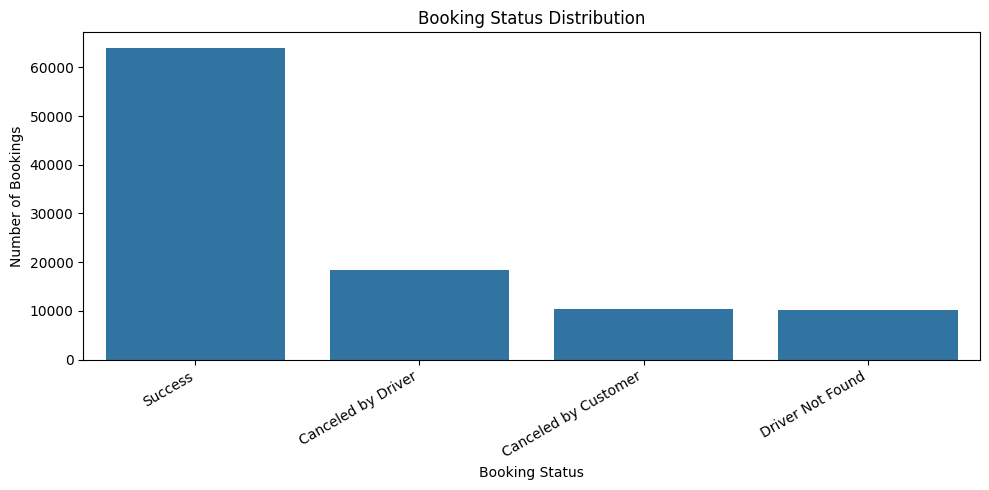

In [22]:

status_counts = df["Booking_Status"].value_counts()

print(status_counts)

plt.figure(figsize=(10, 5))
sns.barplot(x=status_counts.index, y=status_counts.values)

plt.title("Booking Status Distribution")
plt.xlabel("Booking Status")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [23]:
successful = df[df["Booking_Status"] == "Success"].copy()

vehicle_analysis = (
    successful.groupby("Vehicle_Type")
    .agg(
        Successful_Rides=("Booking_ID", "count"),
        Avg_Ride_Distance=("Ride_Distance", "mean"),
        Avg_Booking_Value=("Booking_Value", "mean")
    )
    .round(2)
    .sort_values("Successful_Rides", ascending=False)
)

display(vehicle_analysis)

,Successful_Rides,Avg_Ride_Distance,Avg_Booking_Value
Vehicle_Type,,,
Prime Sedan,9379,25.01,556.99
eBike,9180,25.15,550.62
Auto,9167,10.04,551.09
Bike,9134,24.93,544.34
Prime Plus,9075,25.03,552.64
Mini,9036,24.98,540.72
Prime SUV,8996,24.88,542.11


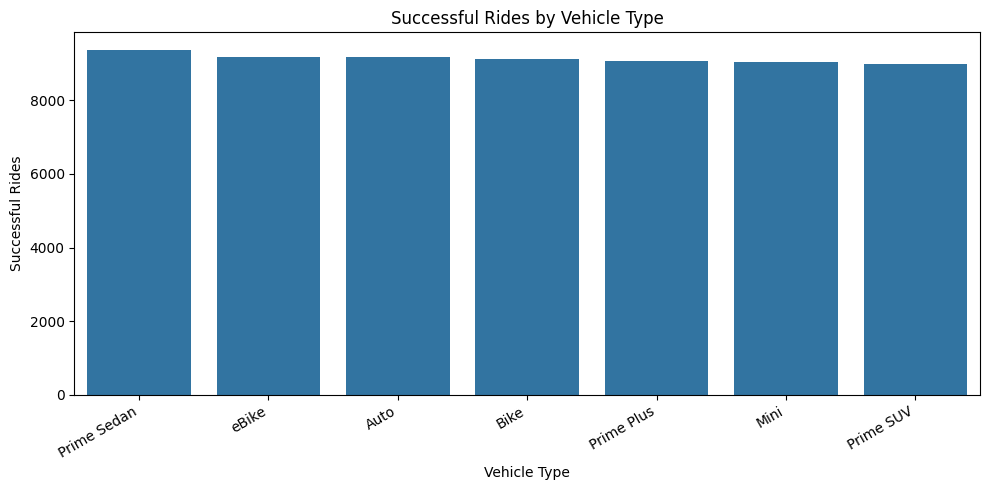

In [24]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=vehicle_analysis.reset_index(),
    x="Vehicle_Type",
    y="Successful_Rides"
)

plt.title("Successful Rides by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Successful Rides")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [25]:
cancelled_statuses = [
    "Canceled by Customer",
    "Canceled by Driver"
]

df["Is_Cancellation"] = df["Booking_Status"].isin(
    cancelled_statuses
)

cancellation_by_vehicle = (
    df.groupby("Vehicle_Type")
    .agg(
        Total_Bookings=("Booking_ID", "count"),
        Cancellations=("Is_Cancellation", "sum")
    )
)

cancellation_by_vehicle["Cancellation_Rate_%"] = (
    100 * cancellation_by_vehicle["Cancellations"]
    / cancellation_by_vehicle["Total_Bookings"]
).round(2)

display(
    cancellation_by_vehicle.sort_values(
        "Cancellation_Rate_%", ascending=False
    )
)

,Total_Bookings,Cancellations,Cancellation_Rate_%
Vehicle_Type,,,
eBike,14816,4206,28.39
Auto,14755,4178,28.32
Prime SUV,14655,4146,28.29
Prime Plus,14707,4157,28.27
Mini,14552,4089,28.10
Bike,14662,4096,27.94
Prime Sedan,14877,4061,27.30


In [27]:
ratings = df.copy()

ratings["Customer_Rating"] = pd.to_numeric(
    ratings["Customer_Rating"].replace("NA", np.nan),
    errors="coerce"
)

rating_analysis = (
    ratings[ratings["Booking_Status"] == "Success"]
    .groupby("Vehicle_Type")
    .agg(
        Rating_Count=("Customer_Rating", "count"),
        Avg_Customer_Rating=("Customer_Rating", "mean")
    )
    .round(2)
    .sort_values("Avg_Customer_Rating", ascending=False)
)

display(rating_analysis)

,Rating_Count,Avg_Customer_Rating
Vehicle_Type,,
Prime Plus,9075,4.01
Mini,9036,4.00
Auto,9167,4.00
Prime Sedan,9379,4.00
Prime SUV,8996,4.00
Bike,9134,3.99
eBike,9180,3.99


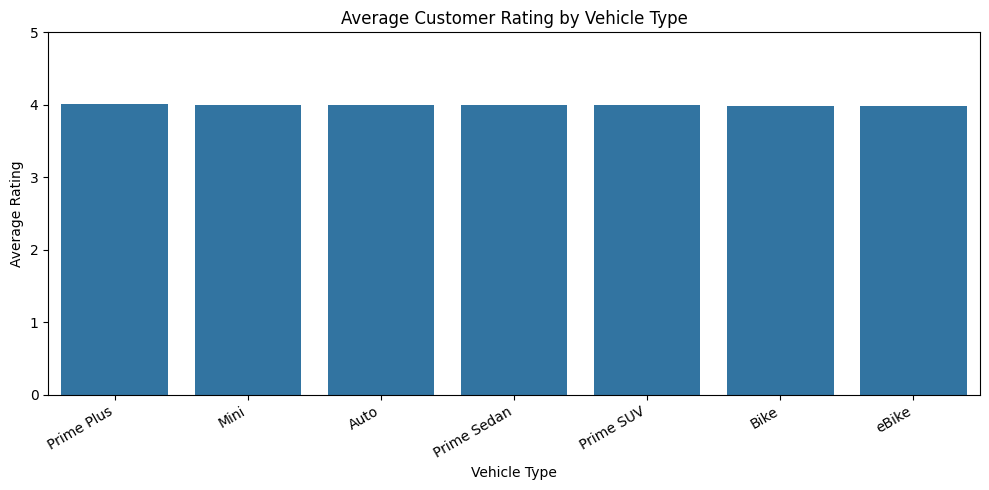

In [28]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=rating_analysis.reset_index(),
    x="Vehicle_Type",
    y="Avg_Customer_Rating"
)

plt.title("Average Customer Rating by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Average Rating")
plt.ylim(0, 5)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [29]:
daily = (
    df.groupby("Date")
    .agg(
        Total_Bookings=("Booking_ID", "count"),
        Successful_Bookings=(
            "Booking_Status",
            lambda s: (s == "Success").sum()
        )
    )
    .sort_index()
)

display(daily.head())

,Total_Bookings,Successful_Bookings
Date,,
2024-07-01,3351,2072
2024-07-02,3388,2122
2024-07-03,3358,2089
2024-07-04,3274,2060
2024-07-05,3306,2063


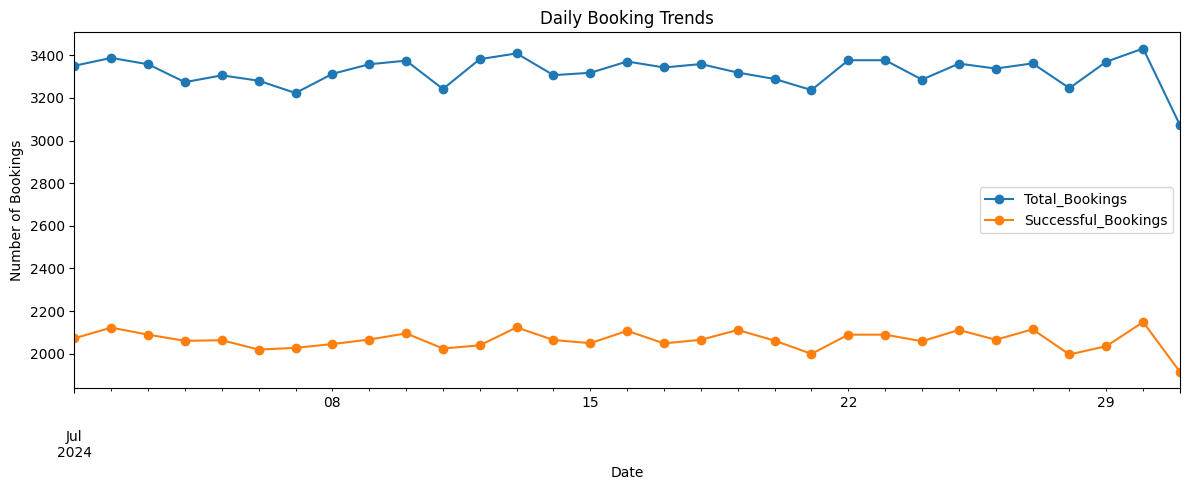

In [30]:
daily.plot(
    figsize=(12, 5),
    marker="o"
)

plt.title("Daily Booking Trends")
plt.xlabel("Date")
plt.ylabel("Number of Bookings")
plt.tight_layout()
plt.show()

In [31]:
successful = df[df["Booking_Status"] == "Success"].copy()

pickup_analysis = (
    successful.groupby("Pickup_Location")
    .agg(
        Successful_Rides=("Booking_ID", "count"),
        Total_Booking_Value=("Booking_Value", "sum"),
        Avg_Ride_Distance=("Ride_Distance", "mean")
    )
    .round(2)
    .sort_values("Successful_Rides", ascending=False)
)

display(pickup_analysis.head(10))

,Successful_Rides,Total_Booking_Value,Avg_Ride_Distance
Pickup_Location,,,
Banashankari,1365,771628,22.85
Yeshwanthpur,1353,748319,23.08
Ramamurthy Nagar,1338,731591,23.06
Cox Town,1335,715618,22.51
Indiranagar,1335,701372,22.67
Basavanagudi,1322,728652,22.65
Magadi Road,1322,734480,22.60
RT Nagar,1321,777106,22.85
Koramangala,1319,708896,23.10


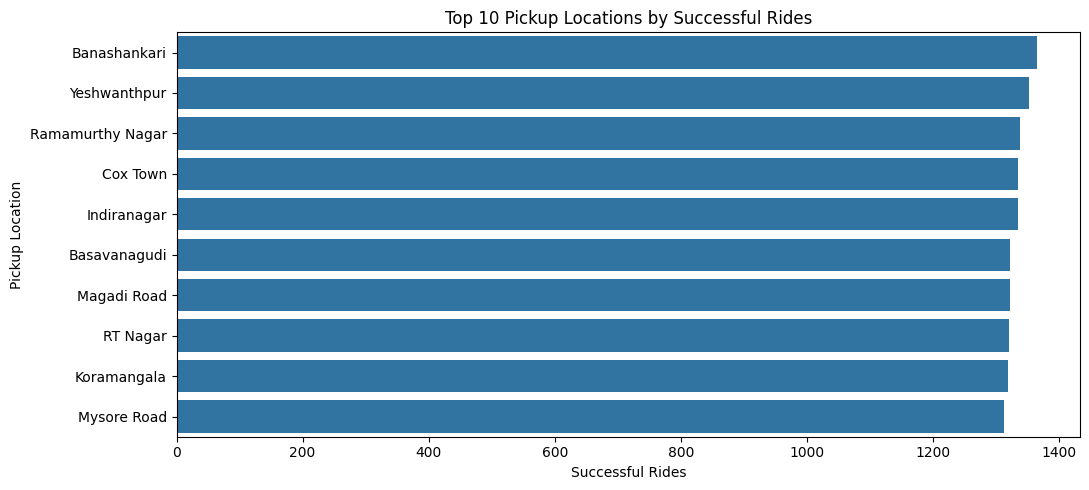

In [32]:
top_pickups = pickup_analysis.head(10).reset_index()

plt.figure(figsize=(11, 5))
sns.barplot(
    data=top_pickups,
    x="Successful_Rides",
    y="Pickup_Location"
)
plt.title("Top 10 Pickup Locations by Successful Rides")
plt.xlabel("Successful Rides")
plt.ylabel("Pickup Location")
plt.tight_layout()
plt.show()

In [33]:
drop_analysis = (
    successful.groupby("Drop_Location")
    .agg(
        Successful_Rides=("Booking_ID", "count"),
        Avg_Ride_Distance=("Ride_Distance", "mean"),
        Total_Booking_Value=("Booking_Value", "sum")
    )
    .round(2)
    .sort_values("Successful_Rides", ascending=False)
)

display(drop_analysis.head(10))

,Successful_Rides,Avg_Ride_Distance,Total_Booking_Value
Drop_Location,,,
Mysore Road,1351,23.20,772450
Bannerghatta Road,1345,23.01,727324
Hebbal,1337,23.18,718159
BTM Layout,1331,23.27,700392
Peenya,1324,23.09,737336
Shivajinagar,1315,23.73,699545
Hennur,1314,22.18,692073
KR Puram,1312,22.76,739224
HSR Layout,1312,22.59,690969


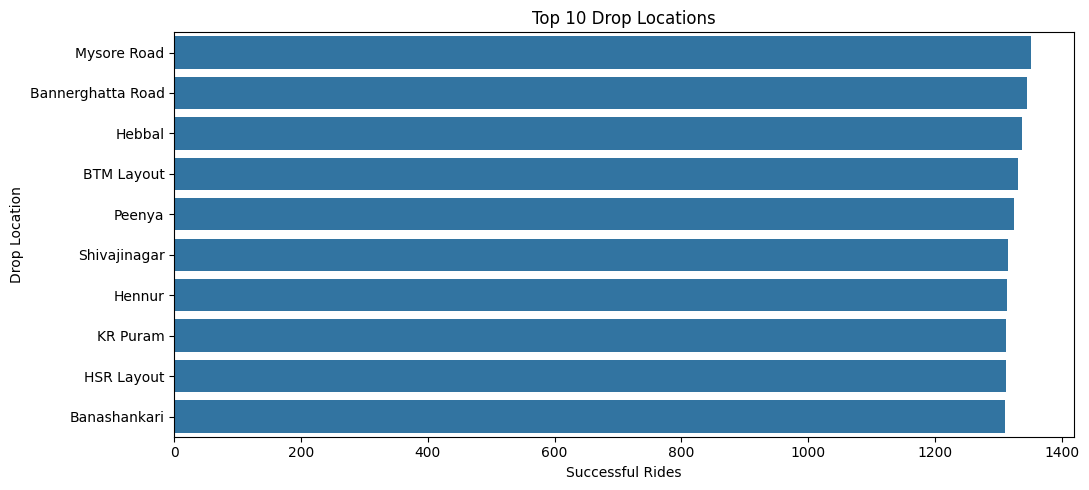

In [34]:
top_drops = drop_analysis.head(10).reset_index()

plt.figure(figsize=(11, 5))
sns.barplot(
    data=top_drops,
    x="Successful_Rides",
    y="Drop_Location"
)
plt.title("Top 10 Drop Locations")
plt.xlabel("Successful Rides")
plt.ylabel("Drop Location")
plt.tight_layout()
plt.show()

In [35]:
df["Time"].head()

0    14:00:00
1    22:20:00
2    19:59:00
3    03:15:00
4    09:02:00
Name: Time, dtype: object

In [36]:
df["Booking_Hour"] = pd.to_datetime(
    df["Time"].astype(str),
    format="%H:%M:%S",
    errors="coerce"
).dt.hour

print("Unparsed time values:", df["Booking_Hour"].isna().sum())

Unparsed time values: 0


In [37]:
hourly_analysis = (
    df.dropna(subset=["Booking_Hour"])
    .groupby("Booking_Hour")
    .agg(
        Total_Bookings=("Booking_ID", "count"),
        Successful_Bookings=(
            "Booking_Status",
            lambda s: (s == "Success").sum()
        )
    )
)

display(hourly_analysis)

,Total_Bookings,Successful_Bookings
Booking_Hour,,
0,4318,2726
1,4329,2697
2,4305,2658
3,4201,2668
4,4263,2651
5,4264,2710
6,4271,2655
7,4304,2628
8,4374,2681


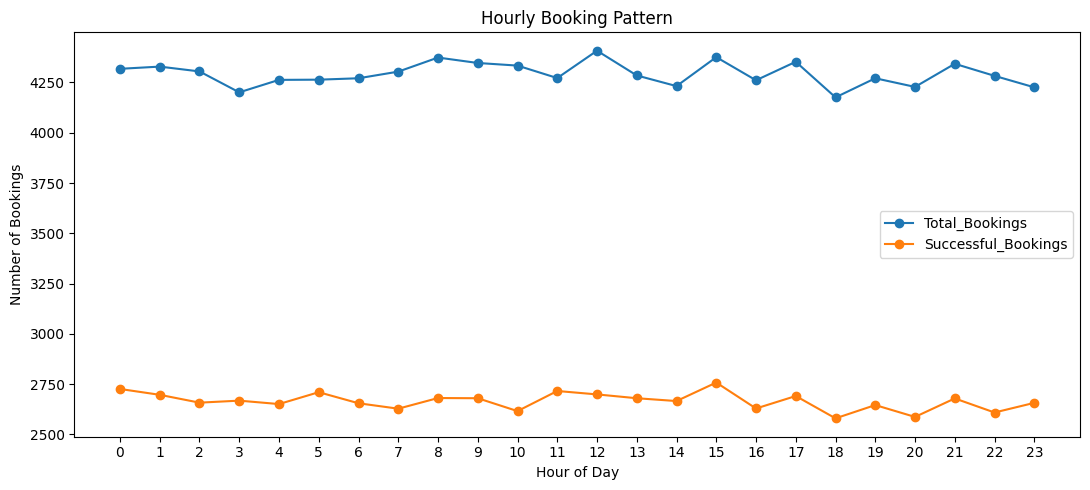

In [38]:
hourly_analysis.plot(
    kind="line",
    figsize=(11, 5),
    marker="o"
)
plt.title("Hourly Booking Pattern")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Bookings")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

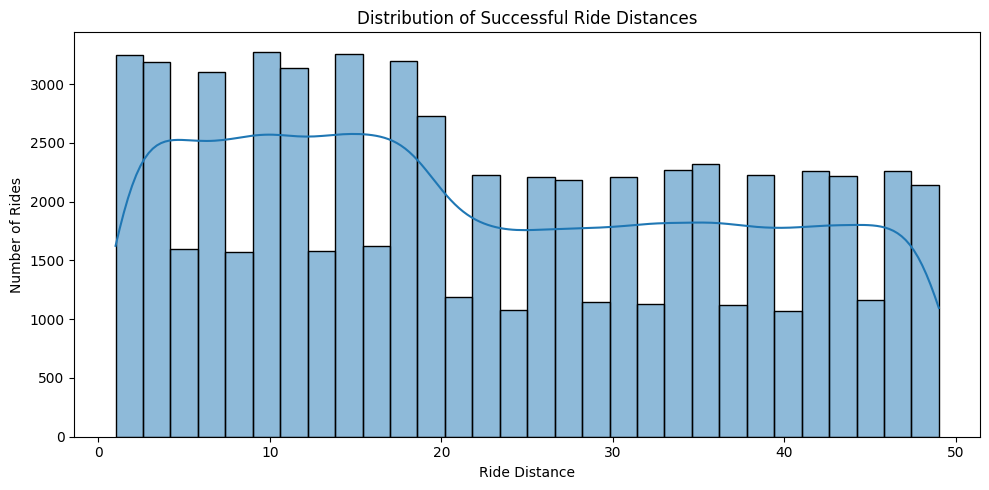

In [39]:
distance = pd.to_numeric(
    successful["Ride_Distance"], errors="coerce"
).dropna()

plt.figure(figsize=(10, 5))
sns.histplot(distance, bins=30, kde=True)
plt.title("Distribution of Successful Ride Distances")
plt.xlabel("Ride Distance")
plt.ylabel("Number of Rides")
plt.tight_layout()
plt.show()

In [40]:
print(distance.describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]))

count    63967.000000
mean        22.854018
std         14.242487
min          1.000000
25%         10.000000
50%         21.000000
75%         35.000000
90%         44.000000
95%         47.000000
max         49.000000
Name: Ride_Distance, dtype: float64


In [41]:
payment_analysis = (
    successful.groupby("Payment_Method")
    .agg(
        Successful_Bookings=("Booking_ID", "count"),
        Total_Booking_Value=("Booking_Value", "sum"),
        Avg_Booking_Value=("Booking_Value", "mean")
    )
    .round(2)
    .sort_values("Successful_Bookings", ascending=False)
)

display(payment_analysis)

,Successful_Bookings,Total_Booking_Value,Avg_Booking_Value
Payment_Method,,,
Cash,35022,19260316,549.95
UPI,25881,14168436,547.45
Credit Card,2435,1312793,539.13
Debit Card,629,338922,538.83


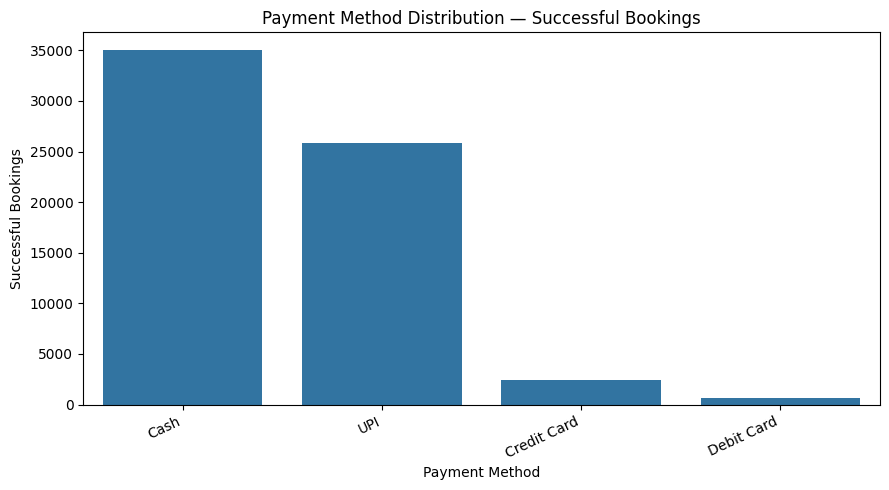

In [42]:
payment_plot = payment_analysis.reset_index()

plt.figure(figsize=(9, 5))
sns.barplot(
    data=payment_plot,
    x="Payment_Method",
    y="Successful_Bookings"
)
plt.title("Payment Method Distribution — Successful Bookings")
plt.xlabel("Payment Method")
plt.ylabel("Successful Bookings")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()